In [ ]:
# ── Step 1: Mount Google Drive ───────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ── Step 2: Copy zip file from Drive to Colab ────────────────────────────────
import shutil

# Change this path to where your zip file is in Google Drive
zip_path = "/content/drive/MyDrive/archive.zip"  # ← change filename if different

shutil.copy(zip_path, "/content/archive.zip")
print("✅ Zip file copied from Drive")


✅ Zip file copied from Drive


In [ ]:
# ── Step 3: Unzip ────────────────────────────────────────────────────────────
import zipfile

with zipfile.ZipFile("/content/archive.zip", 'r') as zip_ref:
    zip_ref.extractall("/content/dataset_raw")

print("✅ Unzipped successfully")

✅ Unzipped successfully


In [ ]:
# ── Step 4: Check folder structure ───────────────────────────────────────────
import os

print("\n📁 Folder structure after unzip:")
for root, dirs, files in os.walk("/content/dataset_raw"):
    level = root.replace("/content/dataset_raw", "").count(os.sep)
    indent = " " * 2 * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 2:
        subindent = " " * 2 * (level + 1)
        for file in files[:3]:   # show first 3 files only
            print(f"{subindent}{file}")


📁 Folder structure after unzip:
dataset_raw/
  Training/
    pituitary/
    meningioma/
    glioma/
    notumor/
  Testing/
    pituitary/
    meningioma/
    glioma/
    notumor/


In [ ]:
import os

print("Inside dataset_raw:")
print(os.listdir("/content/dataset_raw"))

print("\nInside Training:")
print(os.listdir("/content/dataset_raw/Training"))

print("\nInside Testing:")
print(os.listdir("/content/dataset_raw/Testing"))

Inside dataset_raw:
['Training', 'Testing']

Inside Training:
['pituitary', 'meningioma', 'glioma', 'notumor']

Inside Testing:
['pituitary', 'meningioma', 'glioma', 'notumor']


📂 Loading Training data...
  Loading pituitary... 1400 images loaded
  Loading meningioma... 1400 images loaded
  Loading glioma... 1400 images loaded
  Loading notumor... 1400 images loaded

📂 Loading Testing data...
  Loading pituitary... 400 images loaded
  Loading meningioma... 400 images loaded
  Loading glioma... 400 images loaded
  Loading notumor... 400 images loaded

✅ Train : (5600, 128, 128, 3)
✅ Test  : (1600, 128, 128, 3)

📊 Class distribution:
  pituitary    → Train: 1400  Test: 400
  meningioma   → Train: 1400  Test: 400
  glioma       → Train: 1400  Test: 400
  notumor      → Train: 1400  Test: 400

🔧 Building MobileNetV2 model...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ Model built — Total params: 2,619,332

🔥 Phase 1 — Training classifier head (base frozen)...
Epoch 1/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 51s 176ms/step - accuracy: 0.7561 - loss: 0.6295 - val_accuracy: 0.7731 - val_loss: 0.6584 - learning_rate: 0.0010
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 25s 14

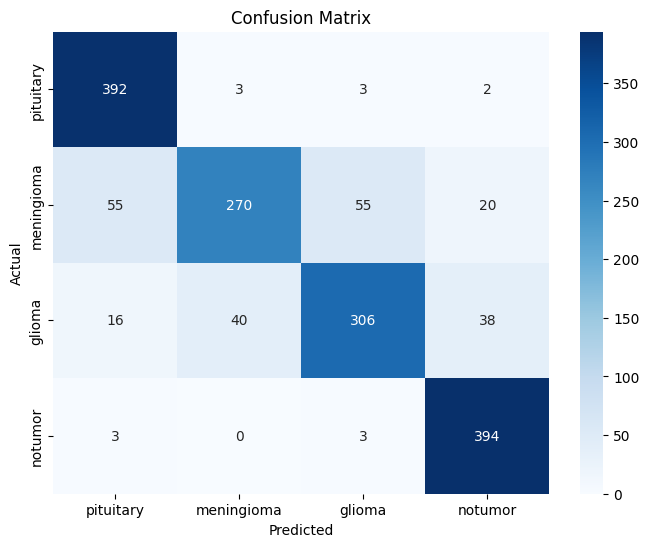


💾 Saving model...
✅ brain_tumor_model.pkl saved to Colab and Google Drive!

🔍 Verifying saved model...
1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step
  Predicted class : pituitary
  Actual class    : pituitary
  Probabilities   : [9.9852473e-01 4.8776533e-04 9.8574674e-04 1.8424587e-06]

🎉 Model ready to use in Streamlit app!


In [ ]:
import numpy as np
import pickle
import os
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from PIL import Image

# ── 1. Config ────────────────────────────────────────────────────────────────
IMG_SIZE        = 128
BATCH_SIZE      = 32
EPOCHS          = 20

TRAIN_PATH      = "/content/dataset_raw/Training"
TEST_PATH       = "/content/dataset_raw/Testing"

# ⚠️ must match exact folder names in your zip
CLASS_NAMES = ['pituitary', 'meningioma', 'glioma', 'notumor']

# ── 2. Load Images Function ──────────────────────────────────────────────────
def load_images(folder_path, class_names):
    images = []
    labels = []
    for idx, class_name in enumerate(class_names):
        class_path = os.path.join(folder_path, class_name)
        print(f"  Loading {class_name}...", end=" ")
        count = 0
        for img_file in os.listdir(class_path):
            try:
                img     = Image.open(os.path.join(class_path, img_file)).convert("RGB")
                img     = img.resize((IMG_SIZE, IMG_SIZE))
                img_arr = np.array(img) / 255.0
                images.append(img_arr)
                labels.append(idx)
                count += 1
            except:
                pass
        print(f"{count} images loaded")
    return np.array(images), np.array(labels)

# ── 3. Load Train and Test Data ──────────────────────────────────────────────
print("📂 Loading Training data...")
X_train, y_train = load_images(TRAIN_PATH, CLASS_NAMES)

print("\n📂 Loading Testing data...")
X_test, y_test = load_images(TEST_PATH, CLASS_NAMES)

print(f"\n✅ Train : {X_train.shape}")
print(f"✅ Test  : {X_test.shape}")

# Check class distribution
print("\n📊 Class distribution:")
for idx, name in enumerate(CLASS_NAMES):
    train_count = np.sum(y_train == idx)
    test_count  = np.sum(y_test == idx)
    print(f"  {name:12} → Train: {train_count}  Test: {test_count}")

# ── 4. One Hot Encode Labels ─────────────────────────────────────────────────
y_train_cat = tf.keras.utils.to_categorical(y_train, 4)
y_test_cat  = tf.keras.utils.to_categorical(y_test,  4)

# ── 5. Data Augmentation ─────────────────────────────────────────────────────
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1
)
train_datagen.fit(X_train)

# ── 6. Build MobileNetV2 Model ───────────────────────────────────────────────
print("\n🔧 Building MobileNetV2 model...")
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

x      = base_model.output
x      = GlobalAveragePooling2D()(x)
x      = Dense(256, activation='relu')(x)
x      = Dropout(0.4)(x)
x      = Dense(128, activation='relu')(x)
x      = Dropout(0.3)(x)
output = Dense(4, activation='softmax')(x)

model  = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(f"✅ Model built — Total params: {model.count_params():,}")

# ── 7. Callbacks ─────────────────────────────────────────────────────────────
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        verbose=1
    )
]

# ── 8. Phase 1 — Train classifier head only ──────────────────────────────────
print("\n🔥 Phase 1 — Training classifier head (base frozen)...")
history1 = model.fit(
    train_datagen.flow(X_train, y_train_cat, batch_size=BATCH_SIZE),
    validation_data=(X_test, y_test_cat),
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

phase1_acc = max(history1.history['val_accuracy']) * 100
print(f"\n✅ Phase 1 Best Val Accuracy: {phase1_acc:.2f}%")

# ── 9. Phase 2 — Fine tune top layers ────────────────────────────────────────
print("\n🔥 Phase 2 — Fine tuning top 30 layers...")
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model.fit(
    train_datagen.flow(X_train, y_train_cat, batch_size=BATCH_SIZE),
    validation_data=(X_test, y_test_cat),
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

phase2_acc = max(history2.history['val_accuracy']) * 100
print(f"\n✅ Phase 2 Best Val Accuracy: {phase2_acc:.2f}%")

# ── 10. Final Evaluation ──────────────────────────────────────────────────────
print("\n📊 Final Evaluation on Test Set:")
loss, acc = model.evaluate(X_test, y_test_cat, verbose=0)
print(f"  Test Accuracy : {acc*100:.2f}%")
print(f"  Test Loss     : {loss:.4f}")

y_pred       = model.predict(X_test)
y_pred_class = np.argmax(y_pred, axis=1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_class, target_names=CLASS_NAMES))

# Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred_class),
    annot=True, fmt='d',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cmap='Blues'
)
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ── 11. Save Model ────────────────────────────────────────────────────────────
print("\n💾 Saving model...")
with open("brain_tumor_model.pkl", "wb") as f:
    pickle.dump(model, f)

# Also save to Drive so you don't lose it
shutil.copy(
    "brain_tumor_model.pkl",
    "/content/drive/MyDrive/brain_tumor_model.pkl"
)

print("✅ brain_tumor_model.pkl saved to Colab and Google Drive!")

# ── 12. Verify Saved Model ────────────────────────────────────────────────────
print("\n🔍 Verifying saved model...")
with open("brain_tumor_model.pkl", "rb") as f:
    loaded_model = pickle.load(f)

test_img  = X_test[0:1]
test_pred = loaded_model.predict(test_img)
print(f"  Predicted class : {CLASS_NAMES[np.argmax(test_pred)]}")
print(f"  Actual class    : {CLASS_NAMES[y_test[0]]}")
print(f"  Probabilities   : {test_pred[0]}")
print("\n🎉 Model ready to use in Streamlit app!")